# Universidad Técnica Nacional
## Minería de datos – ISW 911
### Laboratorio # 4 – Análisis Exploratorio de Datos (EDA)

**Integrante(s):**
- *[Nombre completo] – [Carné]*

---

**Conjunto de datos:** *Recursos (revocatoria y objeción) presentados en procedimientos de contratación pública, 2022‑2024*
**Fuente:** Portal Nacional de Datos Abiertos de Costa Rica (datos.go.cr) – Ministerio de Hacienda, sistema SICOP.
**Enlace original:** https://datos.go.cr/dataset/hacienda-recursos2-2022-2024

Cada fila es un recurso que un proveedor presentó contra un acto de una institución pública
dentro de un procedimiento de contratación (SICOP). El archivo se convirtió de XLSX a CSV (UTF‑8)
y se subió a un repositorio público de GitHub, desde donde se lee en este notebook.

| Columna original | Descripción |
|---|---|
| CEDULA_INSTITUCION | Cédula jurídica de la institución contratante |
| INSTITUCION | Nombre de la institución |
| NUMERO_PROCEDIMIENTO | Número del procedimiento de contratación |
| NRO_RECURSO | Número consecutivo del recurso |
| ASUNTO | Texto libre con el asunto del recurso |
| CEDULA_PROVEEDOR | Cédula del proveedor que recurre |
| PROVEEDOR | Nombre del proveedor |
| NRO_ACTO | Número del acto recurrido (solo aplica a revocatorias) |
| TIPO_RECURSO | Revocatoria u Objeción |
| RESULTADO | Resolución del recurso |
| CAUSA_RESULTADO | Motivo de la resolución |
| FECHA_PRESENTACION_RECURSO | Fecha y hora de presentación |

## 1. Librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

## 2. Lectura del conjunto de datos desde GitHub
El archivo CSV está publicado en un repositorio **público** de GitHub y se lee con la URL *raw*.

In [2]:
URL_GITHUB = "https://raw.githubusercontent.com/Maikelch12/lab4-mineriaDatos/main/datos/recursos_contratacion_2022_2024.csv"

df = pd.read_csv(URL_GITHUB, encoding="utf-8")
print("Dataset cargado:", df.shape)

Origen: datos/recursos_contratacion_2022_2024.csv
Dataset cargado: (34263, 12)


## 3. Funciones básicas para visualizar las principales características
Se usan las funciones básicas de pandas: `shape`, `head`, `tail`, `sample`, `columns`, `info`,
`dtypes`, `describe`, `nunique`, `value_counts` y `duplicated`.

In [3]:
print("Filas:", df.shape[0], "| Columnas:", df.shape[1])
df.head()

Filas: 34263 | Columnas: 12


,CEDULA_INSTITUCION,INSTITUCION,NUMERO_PROCEDIMIENTO,NRO_RECURSO,ASUNTO,CEDULA_PROVEEDOR,PROVEEDOR,NRO_ACTO,TIPO_RECURSO,RESULTADO,CAUSA_RESULTADO,FECHA_PRESENTACION_RECURSO
0,4000042147,CAJA COSTARRICENSE DE SEGURO SOCIAL,2019LN-000001-0001100012,7082022000000886,Recurso de Revocatoria,3101137584,MERCADEO DE ARTICULOS DE CONSUMO SOCIEDAD ANONIMA,707447.0,Revocatoria,Sin lugar,Inadmisible,13/06/2022 15:46:18
1,4000042147,CAJA COSTARRICENSE DE SEGURO SOCIAL,2019LN-000001-0001100012,7082022000000899,Recurso de Revocatoria,3101137584,MERCADEO DE ARTICULOS DE CONSUMO SOCIEDAD ANONIMA,707453.0,Revocatoria,Sin lugar,Inadmisible,13/06/2022 15:46:18
2,4000042147,CAJA COSTARRICENSE DE SEGURO SOCIAL,2019LN-000001-0001100012,7082022000000895,Recurso de Revocatoria,3101137584,MERCADEO DE ARTICULOS DE CONSUMO SOCIEDAD ANONIMA,707451.0,Revocatoria,Sin lugar,Inadmisible,13/06/2022 15:46:18
3,4000042147,CAJA COSTARRICENSE DE SEGURO SOCIAL,2019LN-000001-0001100012,7082022000000875,Recurso de Revocatoria,3101302123,MERCADEO DE CONSUMO MERCONSA SOCIEDAD ANONIMA,707440.0,Revocatoria,Sin lugar,No compete a la institución,13/06/2022 12:18:22
4,4000042147,CAJA COSTARRICENSE DE SEGURO SOCIAL,2019LN-000001-0001100012,7082022000000901,Recurso de Revocatoria,3101137584,MERCADEO DE ARTICULOS DE CONSUMO SOCIEDAD ANONIMA,707440.0,Revocatoria,Sin lugar,Inadmisible,13/06/2022 15:46:18


In [4]:
df.tail()

,CEDULA_INSTITUCION,INSTITUCION,NUMERO_PROCEDIMIENTO,NRO_RECURSO,ASUNTO,CEDULA_PROVEEDOR,PROVEEDOR,NRO_ACTO,TIPO_RECURSO,RESULTADO,CAUSA_RESULTADO,FECHA_PRESENTACION_RECURSO
34258,4000042139,INSTITUTO COSTARRICENSE DE ELECTRICIDAD,2024XE-000296-0000400001,7012024000000073,Recurso de Objeción,3101492990,CORPORACION SUMMATEL SOCIEDAD ANONIMA,NaN,Objeción,Parcialmente con lugar,,19/12/2024 17:39:23
34259,4000042139,INSTITUTO COSTARRICENSE DE ELECTRICIDAD,2024XE-000298-0000400001,7012024000000078,RECURSO DE OBJECION ESPECIFICACIONES,3101631596,GREEN BUILDING TECHNOLOGIES SOCIEDAD ANONIMA,NaN,Objeción,Rechaza de plano,Falta de fundamentación,19/12/2024 21:48:19
34260,4000042139,INSTITUTO COSTARRICENSE DE ELECTRICIDAD,2024XE-000298-0000400001,7012024000000072,Recurso de Objeción,3101492990,CORPORACION SUMMATEL SOCIEDAD ANONIMA,NaN,Objeción,Parcialmente con lugar,,19/12/2024 17:08:07
34261,4000042139,INSTITUTO COSTARRICENSE DE ELECTRICIDAD,2024XE-000298-0000400001,7012024000000077,RECURSO OBJECION PLAZO DE PRESENTACIÓN,3101631596,GREEN BUILDING TECHNOLOGIES SOCIEDAD ANONIMA,NaN,Objeción,Rechaza de plano,Falta de fundamentación,19/12/2024 21:47:43
34262,4000042139,INSTITUTO COSTARRICENSE DE ELECTRICIDAD,2024XE-000300-0000400001,7012024000000079,RECURSO DE OBJECION,3101086923,VMA SERVICIOS INTEGRALES DE LIMPIEZA SOCIEDAD ...,NaN,Objeción,Rechaza de plano,No compete a la institución,20/12/2024 16:33:35


In [5]:
df.sample(5, random_state=42)

,CEDULA_INSTITUCION,INSTITUCION,NUMERO_PROCEDIMIENTO,NRO_RECURSO,ASUNTO,CEDULA_PROVEEDOR,PROVEEDOR,NRO_ACTO,TIPO_RECURSO,RESULTADO,CAUSA_RESULTADO,FECHA_PRESENTACION_RECURSO
25368,3014045149,MUNICIPALIDAD DE VÁSQUEZ DE CORONADO,2024LD-000038-0025000001,7082024000000010,Recurso de revocatoria,107640971,LUIS ANTONIO ALVAREZ CHAVES,1049048.0,Revocatoria,Rechaza de plano,,30/08/2024 18:30:54
31829,3007061394,CONSEJO DE SEGURIDAD VIAL,2024LE-000020-0058700001,7082024000000036,Recurso de Revocatoria,3101174915,NUTRISOL VITE SOCIEDAD ANONIMA,1071612.0,Revocatoria,Con lugar,,15/10/2024 19:42:21
27324,3014042071,MUNICIPALIDAD DE PALMARES,2024LD-000091-0002500001,7082024000000013,Recurso de revocatoria,3102723030,CRETAGAMING SOLUCIONES TECNOLOGICAS SOCIEDAD D...,1106345.0,Revocatoria,Rechaza de plano,Falta de fundamentación,11/12/2024 11:36:41
19793,4000001902,INSTITUTO NACIONAL DE SEGUROS,2023LE-000054-0001000001,7082024000000389,Revocatoria,3101278217,DIALBA NICA SOCIEDAD ANONIMA,997057.0,Revocatoria,Rechaza de plano,,16/05/2024 11:43:15
25514,2200042153,ASAMBLEA LEGISLATIVA,2024LD-000039-0019800001,7082024000000143,REVOCATORIA PARTIDA 37,3101132817,EDICIONES IBEROAMERICANAS SOCIEDAD ANONIMA,1048702.0,Revocatoria,Sin lugar,,30/08/2024 11:29:21


In [6]:
df.columns.tolist()

['CEDULA_INSTITUCION',
 'INSTITUCION',
 'NUMERO_PROCEDIMIENTO',
 'NRO_RECURSO',
 'ASUNTO',
 'CEDULA_PROVEEDOR',
 'PROVEEDOR',
 'NRO_ACTO',
 'TIPO_RECURSO',
 'RESULTADO',
 'CAUSA_RESULTADO',
 'FECHA_PRESENTACION_RECURSO']

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 34263 entries, 0 to 34262
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   CEDULA_INSTITUCION          34263 non-null  int64  
 1   INSTITUCION                 34263 non-null  str    
 2   NUMERO_PROCEDIMIENTO        34263 non-null  str    
 3   NRO_RECURSO                 34263 non-null  int64  
 4   ASUNTO                      34263 non-null  str    
 5   CEDULA_PROVEEDOR            34263 non-null  int64  
 6   PROVEEDOR                   34263 non-null  str    
 7   NRO_ACTO                    22141 non-null  float64
 8   TIPO_RECURSO                34263 non-null  str    
 9   RESULTADO                   34263 non-null  str    
 10  CAUSA_RESULTADO             34263 non-null  str    
 11  FECHA_PRESENTACION_RECURSO  34263 non-null  str    
dtypes: float64(1), int64(3), str(8)
memory usage: 3.1 MB


In [8]:
df.dtypes

CEDULA_INSTITUCION              int64
INSTITUCION                       str
NUMERO_PROCEDIMIENTO              str
NRO_RECURSO                     int64
ASUNTO                            str
CEDULA_PROVEEDOR                int64
PROVEEDOR                         str
NRO_ACTO                      float64
TIPO_RECURSO                      str
RESULTADO                         str
CAUSA_RESULTADO                   str
FECHA_PRESENTACION_RECURSO        str
dtype: object

In [9]:
# Estadísticas descriptivas de las columnas numéricas
df.describe()

,CEDULA_INSTITUCION,NRO_RECURSO,CEDULA_PROVEEDOR,NRO_ACTO
count,3.426300e+04,3.426300e+04,3.426300e+04,2.214100e+04
mean,3.540548e+09,7.057258e+15,3.002313e+09,9.035657e+05
std,5.851789e+08,3.347063e+13,3.889751e+09,1.215170e+05
min,2.100042e+09,7.012022e+15,1.035204e+08,1.000000e+00
25%,3.014042e+09,7.012024e+15,3.101113e+09,8.016930e+05
50%,4.000002e+09,7.082022e+15,3.101258e+09,9.032380e+05
75%,4.000042e+09,7.082023e+15,3.101633e+09,1.007363e+06
max,4.000153e+09,7.082024e+15,1.862010e+11,1.113861e+06


In [10]:
# Estadísticas descriptivas de las columnas de texto (categóricas)
df.describe(include="object")

,INSTITUCION,NUMERO_PROCEDIMIENTO,ASUNTO,PROVEEDOR,TIPO_RECURSO,RESULTADO,CAUSA_RESULTADO,FECHA_PRESENTACION_RECURSO
count,34263,34263,34263,34263,34263,34263,34263,34263
unique,312,14567,8818,3125,3,5,8,25802
top,CAJA COSTARRICENSE DE SEGURO SOCIAL,2023LE-000037-0001000001,RECURSO DE REVOCATORIA,SERVICIOS TECNICOS PROTESICOS SOCIEDAD ANONIMA,Revocatoria,Rechaza de plano,,30/08/2024 11:29:21
freq,12401,276,1979,766,22140,12591,19935,198


In [11]:
# Cantidad de valores distintos por columna
df.nunique().sort_values()

TIPO_RECURSO                      3
RESULTADO                         5
CAUSA_RESULTADO                   8
INSTITUCION                     312
CEDULA_INSTITUCION              316
PROVEEDOR                      3125
CEDULA_PROVEEDOR               3126
ASUNTO                         8818
NRO_RECURSO                   12697
NUMERO_PROCEDIMIENTO          14567
NRO_ACTO                      18870
FECHA_PRESENTACION_RECURSO    25802
dtype: int64

In [12]:
# Distribución de las variables categóricas principales
for col in ["TIPO_RECURSO", "RESULTADO", "CAUSA_RESULTADO"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False), "\n")

--- TIPO_RECURSO ---
TIPO_RECURSO
Revocatoria    22140
Objeción       12122
AC                 1
Name: count, dtype: int64 

--- RESULTADO ---
RESULTADO
Rechaza de plano          12591
Sin lugar                  9177
Con lugar                  7005
Parcialmente con lugar     5458
                             32
Name: count, dtype: int64 

--- CAUSA_RESULTADO ---
CAUSA_RESULTADO
                                      19935
Falta de fundamentación                3589
No compete a la institución            3098
Declaración sin lugar por el fondo     1862
Inadmisible                            1841
Falta de legitimación                  1648
Extemporáneo                           1562
Improcedencia manifiesta                728
Name: count, dtype: int64 



In [13]:
print("Top 10 instituciones con más recursos:")
df["INSTITUCION"].value_counts().head(10)

Top 10 instituciones con más recursos:


INSTITUCION
CAJA COSTARRICENSE DE SEGURO SOCIAL                        12401
INSTITUTO NACIONAL DE SEGUROS                               3210
UNIVERSIDAD DE COSTA RICA                                    724
INSTITUTO NACIONAL DE APRENDIZAJE                            675
MUNICIPALIDAD DEL CANTÓN CENTRAL DE SAN JOSÉ                 556
UNIVERSIDAD NACIONAL                                         531
REFINADORA COSTARRICENSE DE PETRÓLEO SOCIEDAD ANÓNIMA        506
INSTITUTO COSTARRICENSE DE ELECTRICIDAD                      464
UNIVERSIDAD TÉCNICA NACIONAL                                 441
INSTITUTO COSTARRICENSE DE ACUEDUCTOS Y ALCANTARILLADOS      392
Name: count, dtype: int64

In [14]:
print("Filas duplicadas:", df.duplicated().sum())
print("Memoria utilizada: %.2f MB" % (df.memory_usage(deep=True).sum() / 1024**2))

Filas duplicadas: 0
Memoria utilizada: 21.88 MB


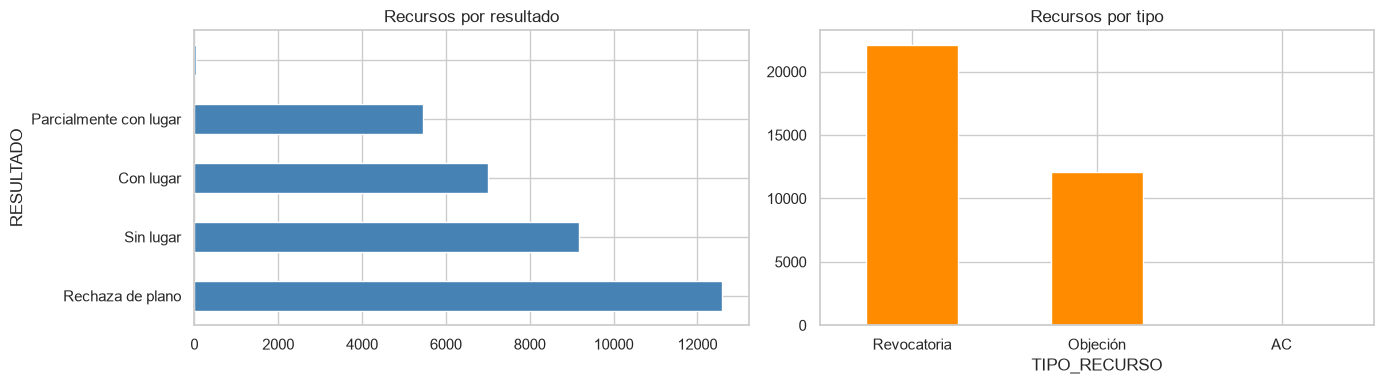

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df["RESULTADO"].value_counts().plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title("Recursos por resultado")
df["TIPO_RECURSO"].value_counts().plot.bar(ax=axes[1], color="darkorange", rot=0)
axes[1].set_title("Recursos por tipo")
plt.tight_layout(); plt.show()

**Observaciones iniciales**
- 34 263 registros y 12 columnas; no hay filas duplicadas.
- Varias columnas son identificadores (cédulas, números de procedimiento/recurso/acto) que pandas
  infirió como numéricas, pero no son cantidades: se deben tratar como texto.
- `RESULTADO` y `CAUSA_RESULTADO` contienen valores que son solo espacios en blanco (`" "`),
  que en realidad son **valores faltantes ocultos**.
- `TIPO_RECURSO` tiene un valor `AC` con un único registro (valor inválido).
- `FECHA_PRESENTACION_RECURSO` se cargó como texto.

## 4. Cambio de nombres de las columnas a español
Las columnas originales vienen en mayúsculas, abreviadas (`NRO_`) y sin tildes.
Se renombran a nombres en español, descriptivos y en formato `snake_case`.

In [16]:
nombres_columnas = {
    "CEDULA_INSTITUCION": "cedula_institucion",
    "INSTITUCION": "institucion",
    "NUMERO_PROCEDIMIENTO": "numero_procedimiento",
    "NRO_RECURSO": "numero_recurso",
    "ASUNTO": "asunto",
    "CEDULA_PROVEEDOR": "cedula_proveedor",
    "PROVEEDOR": "proveedor",
    "NRO_ACTO": "numero_acto_recurrido",
    "TIPO_RECURSO": "tipo_recurso",
    "RESULTADO": "resultado",
    "CAUSA_RESULTADO": "causa_resultado",
    "FECHA_PRESENTACION_RECURSO": "fecha_presentacion",
}
df = df.rename(columns=nombres_columnas)
df.columns.tolist()

['cedula_institucion',
 'institucion',
 'numero_procedimiento',
 'numero_recurso',
 'asunto',
 'cedula_proveedor',
 'proveedor',
 'numero_acto_recurrido',
 'tipo_recurso',
 'resultado',
 'causa_resultado',
 'fecha_presentacion']

## 5. Detección de valores nulos
Primero se convierten a `NaN` los textos vacíos o compuestos solo por espacios, ya que pandas
no los reconoce como nulos. Luego se cuantifican y se grafican.

In [17]:
def limpiar_vacios(data):
    """Convierte cadenas vacías o con solo espacios en NaN y quita espacios sobrantes."""
    data = data.copy()
    for col in data.select_dtypes(include="object").columns:
        data[col] = data[col].str.strip().replace("", np.nan)
    return data

print("Nulos ANTES de limpiar vacíos:", df.isna().sum().sum())
df = limpiar_vacios(df)
print("Nulos DESPUÉS de limpiar vacíos:", df.isna().sum().sum())

Nulos ANTES de limpiar vacíos: 12122
Nulos DESPUÉS de limpiar vacíos: 32089


In [18]:
nulos = pd.DataFrame({
    "nulos": df.isnull().sum(),
    "porcentaje": (df.isnull().mean() * 100).round(2)
}).sort_values("porcentaje", ascending=False)
nulos

,nulos,porcentaje
causa_resultado,19935,58.18
numero_acto_recurrido,12122,35.38
resultado,32,0.09
cedula_institucion,0,0.00
numero_recurso,0,0.00
numero_procedimiento,0,0.00
institucion,0,0.00
asunto,0,0.00
proveedor,0,0.00
cedula_proveedor,0,0.00


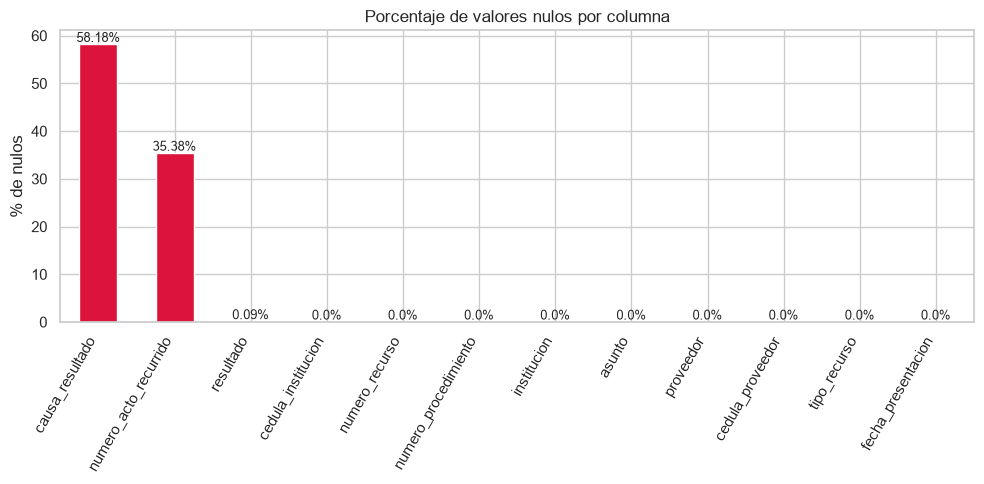

In [19]:
# Evidencia gráfica 1: porcentaje de nulos por columna
ax = nulos["porcentaje"].plot.bar(color=["crimson" if p > 0 else "gray" for p in nulos["porcentaje"]])
ax.set_title("Porcentaje de valores nulos por columna")
ax.set_ylabel("% de nulos")
for i, v in enumerate(nulos["porcentaje"]):
    ax.text(i, v + 0.5, f"{v}%", ha="center", fontsize=9)
plt.xticks(rotation=60, ha="right"); plt.tight_layout(); plt.show()

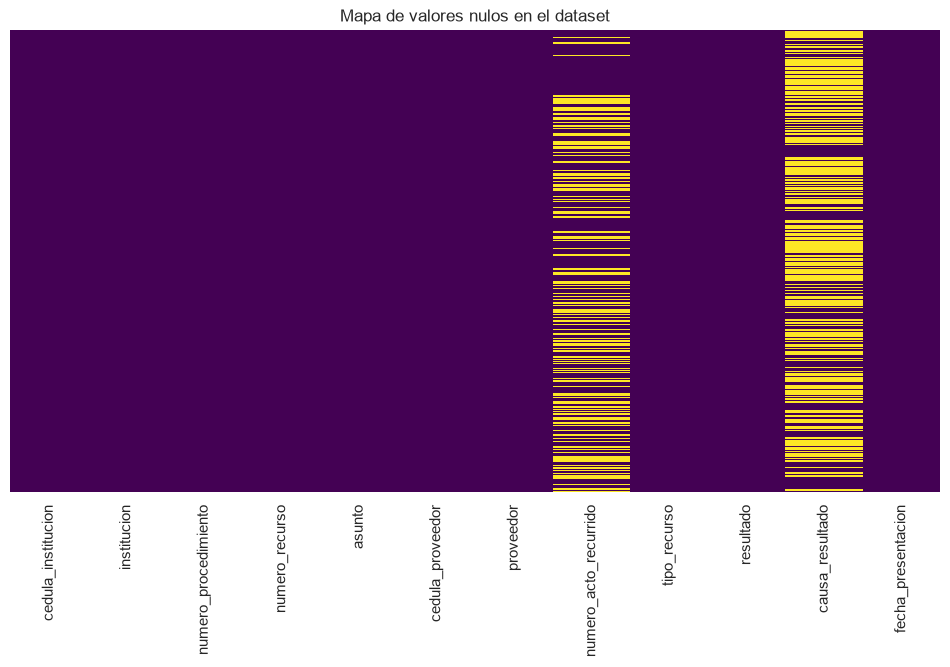

In [20]:
# Evidencia gráfica 2: mapa de calor de nulos (cada línea amarilla es un valor faltante)
plt.figure(figsize=(12, 6))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Mapa de valores nulos en el dataset")
plt.show()

In [21]:
# ¿Los nulos de numero_acto_recurrido dependen del tipo de recurso?
pd.crosstab(df["tipo_recurso"], df["numero_acto_recurrido"].isna(), margins=True,
            rownames=["tipo_recurso"], colnames=["acto_es_nulo"])

acto_es_nulo,False,True,All
tipo_recurso,,,
AC,1,0,1
Objeción,0,12122,12122
Revocatoria,22140,0,22140
All,22141,12122,34263


In [22]:
# ¿Los nulos de causa_resultado dependen del resultado?
pd.crosstab(df["resultado"].fillna("NULO"), df["causa_resultado"].isna(),
            rownames=["resultado"], colnames=["causa_es_nula"])

causa_es_nula,False,True
resultado,,
Con lugar,0,7005
NULO,0,32
Parcialmente con lugar,0,5458
Rechaza de plano,9451,3140
Sin lugar,4877,4300


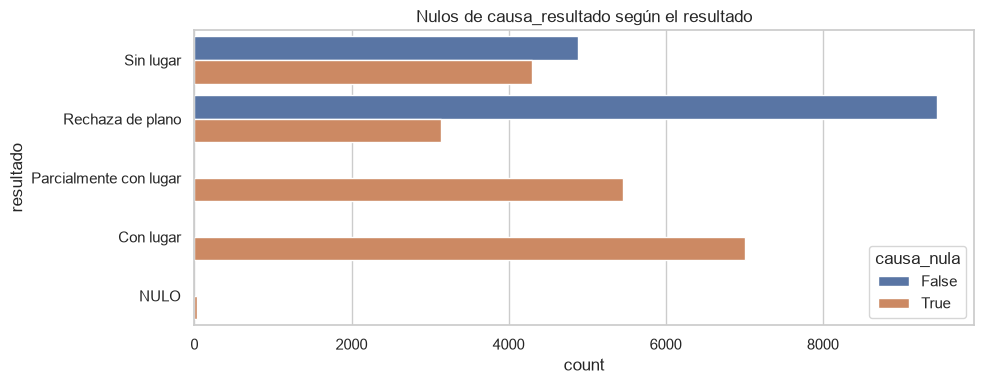

In [23]:
plt.figure(figsize=(10, 4))
sns.countplot(data=df.assign(causa_nula=df["causa_resultado"].isna()),
              y=df["resultado"].fillna("NULO"), hue="causa_nula")
plt.title("Nulos de causa_resultado según el resultado")
plt.tight_layout(); plt.show()

**Hallazgos sobre nulos**
- `causa_resultado` (~58 %): la institución no siempre registra una causa. El 100 % de los recursos
  *Con lugar* y *Parcialmente con lugar* no tienen causa (la causa solo se registra al rechazar).
  El nulo es **informativo**, no un error.
- `numero_acto_recurrido` (~35 %): **nulo estructural**. El 100 % de los nulos son recursos de
  *Objeción*, que se presentan contra el pliego de condiciones y no contra un acto, por lo que no
  existe un número de acto.
- `resultado` (32 filas, 0,09 %): recursos sin resolución registrada. Es la variable objetivo.

## 6. Detección de valores atípicos
Las columnas numéricas originales son identificadores, por lo que no tiene sentido buscar atípicos
en ellas. Se construyen variables numéricas con significado analítico:

- `recursos_por_procedimiento`: cantidad de recursos que recibió el mismo procedimiento.
- `recursos_por_proveedor`: cantidad de recursos que presentó el mismo proveedor.
- `recursos_por_institucion`: cantidad de recursos recibidos por la institución.
- `hora_presentacion`: hora del día en que se presentó el recurso.

Se utiliza el método del **rango intercuartílico (IQR)**: es atípico todo valor fuera de
`[Q1 − 1,5·IQR , Q3 + 1,5·IQR]`.

In [24]:
fecha_tmp = pd.to_datetime(df["fecha_presentacion"], format="%d/%m/%Y %H:%M:%S")
df["recursos_por_procedimiento"] = df.groupby("numero_procedimiento")["numero_recurso"].transform("count")
df["recursos_por_proveedor"] = df.groupby("cedula_proveedor")["numero_recurso"].transform("count")
df["recursos_por_institucion"] = df.groupby("cedula_institucion")["numero_recurso"].transform("count")
df["hora_presentacion"] = fecha_tmp.dt.hour

variables_numericas = ["recursos_por_procedimiento", "recursos_por_proveedor",
                       "recursos_por_institucion", "hora_presentacion"]
df[variables_numericas].describe()

,recursos_por_procedimiento,recursos_por_proveedor,recursos_por_institucion,hora_presentacion
count,34263.000000,34263.000000,34263.000000,34263.000000
mean,24.074220,129.417126,4912.428830,14.844876
std,51.519801,173.417967,5704.866357,4.092249
min,1.000000,1.000000,1.000000,0.000000
25%,1.000000,14.000000,136.000000,12.000000
50%,3.000000,53.000000,556.000000,15.000000
75%,14.000000,156.000000,12401.000000,17.000000
max,276.000000,766.000000,12401.000000,23.000000


In [25]:
def detectar_atipicos_iqr(data, columna, factor=1.5):
    """Devuelve los límites inferior/superior del IQR y la cantidad de atípicos."""
    q1, q3 = data[columna].quantile([0.25, 0.75])
    iqr = q3 - q1
    li, ls = q1 - factor * iqr, q3 + factor * iqr
    mascara = (data[columna] < li) | (data[columna] > ls)
    return li, ls, mascara.sum()

resumen_atipicos = []
for col in variables_numericas:
    li, ls, n = detectar_atipicos_iqr(df, col)
    resumen_atipicos.append({"variable": col, "limite_inferior": li, "limite_superior": ls,
                             "atipicos": n, "porcentaje": round(n / len(df) * 100, 2)})
resumen_atipicos = pd.DataFrame(resumen_atipicos)
resumen_atipicos

,variable,limite_inferior,limite_superior,atipicos,porcentaje
0,recursos_por_procedimiento,-18.5,33.5,6034,17.61
1,recursos_por_proveedor,-199.0,369.0,3581,10.45
2,recursos_por_institucion,-18261.5,30798.5,0,0.00
3,hora_presentacion,4.5,24.5,268,0.78


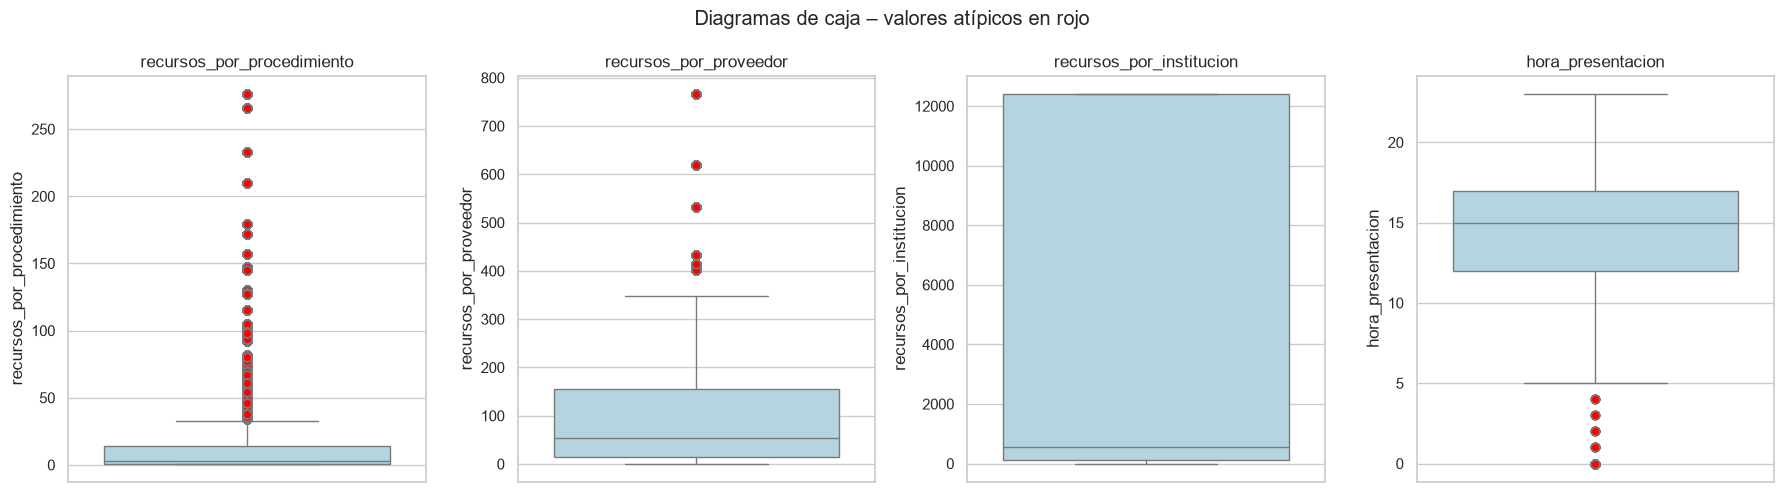

In [26]:
# Evidencia gráfica 1: diagramas de caja
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, col in zip(axes, variables_numericas):
    sns.boxplot(y=df[col], ax=ax, color="lightblue", flierprops={"markerfacecolor": "red"})
    ax.set_title(col)
plt.suptitle("Diagramas de caja – valores atípicos en rojo"); plt.tight_layout(); plt.show()

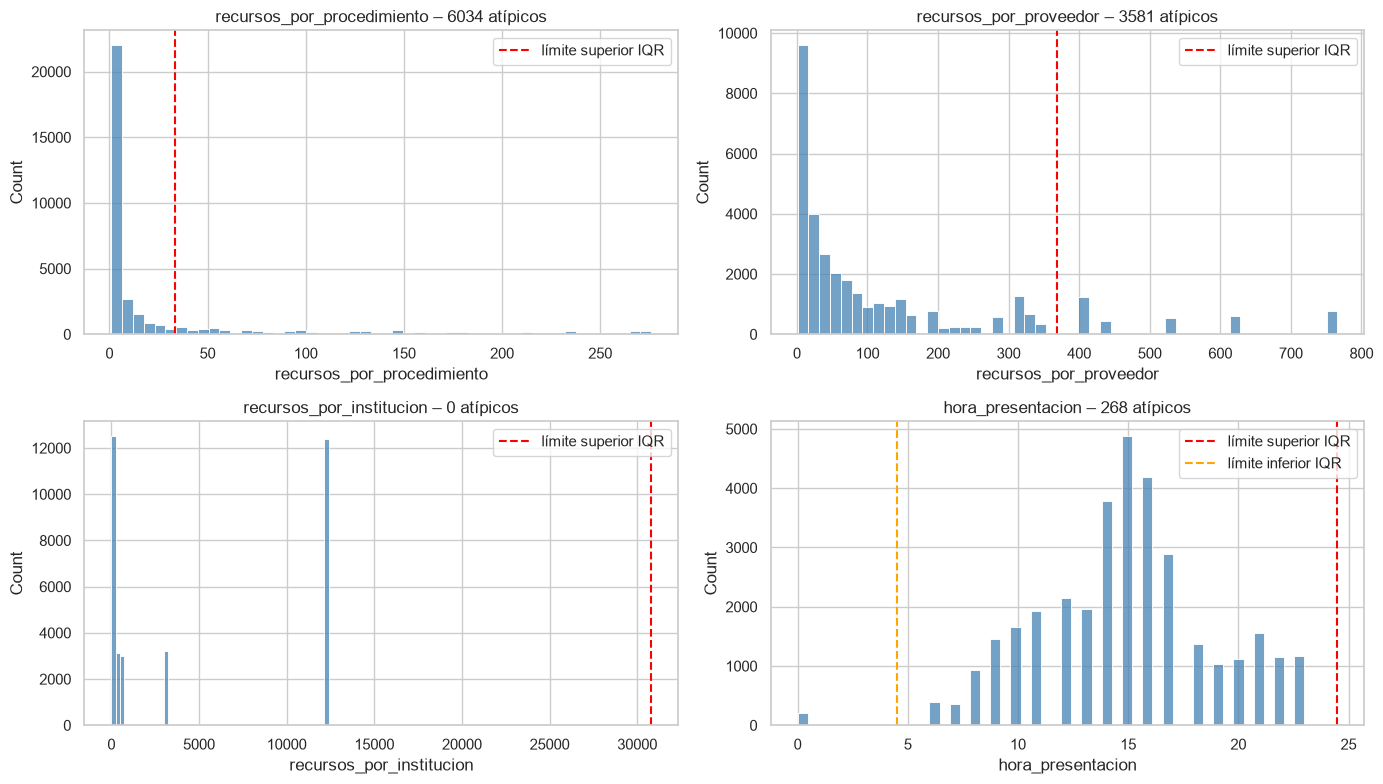

In [27]:
# Evidencia gráfica 2: histogramas con los límites del IQR
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (_, fila) in zip(axes.ravel(), resumen_atipicos.iterrows()):
    sns.histplot(df[fila["variable"]], bins=50, ax=ax, color="steelblue")
    ax.axvline(fila["limite_superior"], color="red", ls="--", label="límite superior IQR")
    if fila["limite_inferior"] > df[fila["variable"]].min():
        ax.axvline(fila["limite_inferior"], color="orange", ls="--", label="límite inferior IQR")
    ax.set_title(f"{fila['variable']} – {fila['atipicos']} atípicos"); ax.legend()
plt.tight_layout(); plt.show()

In [28]:
# Procedimientos y proveedores con más recursos (los casos extremos)
print(df.groupby("numero_procedimiento").size().sort_values(ascending=False).head(5), "\n")
print(df.groupby("proveedor").size().sort_values(ascending=False).head(5))

numero_procedimiento
2023LE-000037-0001000001    276
2024LE-000027-0001000001    266
2023LE-000018-0001000001    233
2024LD-000039-0019800001    210
2023LE-000007-0001102504    179
dtype: int64 

proveedor
SERVICIOS TECNICOS PROTESICOS SOCIEDAD ANONIMA                     766
CQ MEDICAL CENTROAMERICANA SOCIEDAD DE RESPONSABILIDAD LIMITADA    620
NUTRICARE SOCIEDAD ANONIMA                                         533
3-102-849409 SOCIEDAD DE RESPONSABILIDAD LIMITADA                  433
MEDITEK SERVICES SOCIEDAD ANONIMA                                  414
dtype: int64


**Hallazgos sobre atípicos**
- `recursos_por_procedimiento` y `recursos_por_proveedor` tienen distribuciones muy sesgadas a la
  derecha: la mayoría tiene 1‑2 recursos, pero hay procedimientos con cientos de recursos
  (licitaciones de la CCSS con muchas líneas) y proveedores que recurren cientos de veces.
  Por IQR son atípicos el ~17,6 % y ~10,5 % de las filas, respectivamente.
- `recursos_por_institucion` está dominada por la CCSS (12 401 recursos, ~36 % del total). Como la
  CCSS concentra más de un cuarto de las filas, cae dentro del rango intercuartílico y el IQR **no**
  la marca como atípica, aunque el histograma evidencia una distribución bimodal muy desbalanceada.
- `hora_presentacion` tiene 268 recursos presentados de madrugada (0‑4 h), fuera del horario habitual.
- Son valores **reales** (no errores de digitación), por lo que no se eliminan: se tratan con
  acotamiento (*capping*) en el siguiente paso.

## 7. Funciones de imputación y tratamiento
Se crean funciones reutilizables. La justificación de cada acción se documenta en cada función.

In [29]:
def eliminar_nulos_variable_objetivo(data, columna):
    """
    JUSTIFICACIÓN: 'resultado' es la variable dependiente. Imputarla inventaría la etiqueta que el
    modelo debe aprender e introduciría sesgo. Como solo son 32 filas (0,09 %), se eliminan.
    """
    antes = len(data)
    data = data.dropna(subset=[columna]).copy()
    print(f"{columna}: se eliminaron {antes - len(data)} filas sin valor.")
    return data


def eliminar_categorias_invalidas(data, columna, validas):
    """
    JUSTIFICACIÓN: 'tipo_recurso' solo admite 'Revocatoria' u 'Objeción'. El valor 'AC' aparece una
    sola vez y no corresponde a ningún tipo de recurso: es un error de registro y se elimina.
    """
    antes = len(data)
    data = data[data[columna].isin(validas)].copy()
    print(f"{columna}: se eliminaron {antes - len(data)} filas con categorías inválidas.")
    return data


def imputar_categorica_constante(data, columna, valor):
    """
    JUSTIFICACIÓN: en 'causa_resultado' el nulo significa que la institución no indicó causa
    (sucede sobre todo cuando el recurso se acoge). Imputar con la moda ('Falta de fundamentación')
    sería falso y distorsionaría la distribución en el 58 % de las filas. Se imputa con una
    categoría explícita para conservar la información de que no hubo causa.
    """
    n = data[columna].isna().sum()
    data[columna] = data[columna].fillna(valor)
    print(f"{columna}: {n} nulos imputados con '{valor}'.")
    return data


def imputar_nulo_estructural(data, columna, valor=0):
    """
    JUSTIFICACIÓN: 'numero_acto_recurrido' es nulo únicamente en recursos de Objeción, que no tienen
    acto recurrido. No es un dato perdido, sino 'no aplica'. Se crea un indicador binario
    'tiene_acto_recurrido' y el valor faltante se rellena con 0 (código 'no aplica').
    La media o mediana no tienen sentido porque es un identificador.
    """
    data["tiene_acto_recurrido"] = data[columna].notna().astype(int)
    n = data[columna].isna().sum()
    data[columna] = data[columna].fillna(valor)
    print(f"{columna}: {n} nulos estructurales reemplazados por {valor}; se creó 'tiene_acto_recurrido'.")
    return data


def imputar_numerica_mediana(data, columna):
    """
    Imputación genérica para variables numéricas: se usa la MEDIANA porque, a diferencia de la
    media, es robusta ante los valores atípicos detectados en el punto anterior.
    """
    n = data[columna].isna().sum()
    if n:
        data[columna] = data[columna].fillna(data[columna].median())
    print(f"{columna}: {n} nulos imputados con la mediana.")
    return data


def tratar_atipicos_capping(data, columna, factor=1.5):
    """
    JUSTIFICACIÓN: los atípicos son reales (un procedimiento grande sí puede recibir 276 recursos),
    así que eliminarlos perdería información. Se acotan (winsorización) a los límites del IQR para
    que no dominen la estandarización ni los modelos sensibles a escala, conservando todas las filas.
    """
    li, ls, n = detectar_atipicos_iqr(data, columna, factor)
    data[columna] = data[columna].clip(lower=li, upper=ls)
    print(f"{columna}: {n} atípicos acotados al rango [{li:.2f}, {ls:.2f}].")
    return data

In [30]:
df = eliminar_nulos_variable_objetivo(df, "resultado")
df = eliminar_categorias_invalidas(df, "tipo_recurso", ["Revocatoria", "Objeción"])
df = imputar_categorica_constante(df, "causa_resultado", "Sin causa registrada")
df = imputar_nulo_estructural(df, "numero_acto_recurrido", 0)
for col in variables_numericas:
    df = imputar_numerica_mediana(df, col)

# Se conserva una copia sin acotar para comparar
df_antes_capping = df[variables_numericas].copy()
for col in ["recursos_por_procedimiento", "recursos_por_proveedor", "recursos_por_institucion"]:
    df = tratar_atipicos_capping(df, col)

resultado: se eliminaron 32 filas sin valor.
tipo_recurso: se eliminaron 1 filas con categorías inválidas.
causa_resultado: 19903 nulos imputados con 'Sin causa registrada'.
numero_acto_recurrido: 12122 nulos estructurales reemplazados por 0; se creó 'tiene_acto_recurrido'.
recursos_por_procedimiento: 0 nulos imputados con la mediana.
recursos_por_proveedor: 0 nulos imputados con la mediana.
recursos_por_institucion: 0 nulos imputados con la mediana.
hora_presentacion: 0 nulos imputados con la mediana.
recursos_por_procedimiento: 6034 atípicos acotados al rango [-18.50, 33.50].
recursos_por_proveedor: 3578 atípicos acotados al rango [-199.00, 369.00].
recursos_por_institucion: 0 atípicos acotados al rango [-18261.50, 30798.50].


> `hora_presentacion` **no** se acota: sus valores (0‑23) son todos válidos; las horas de madrugada
> son un comportamiento real que puede aportar información.

Nulos restantes: 0


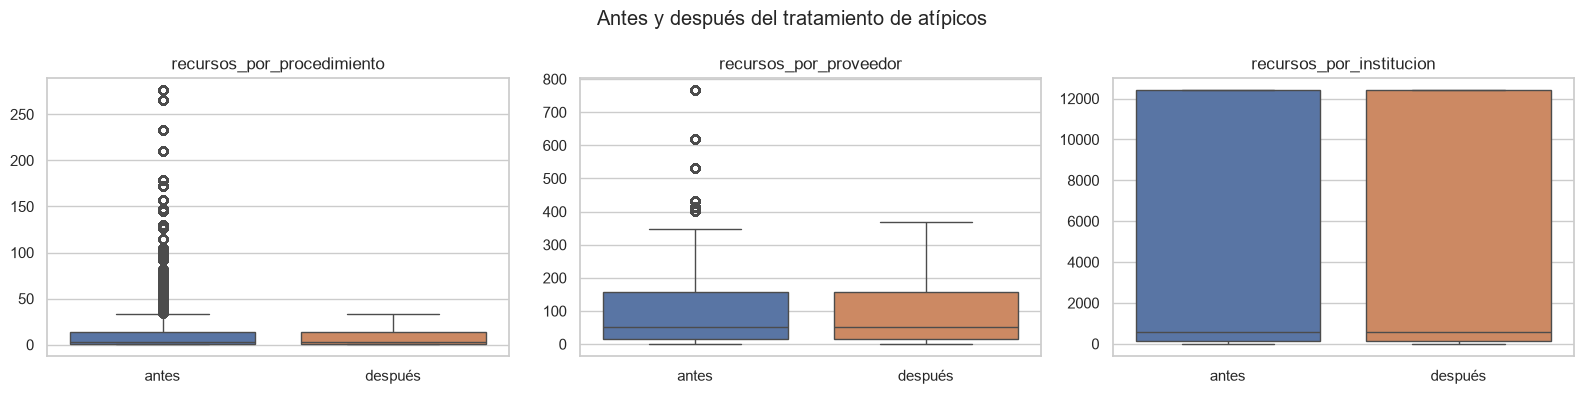

In [31]:
# Verificación: ya no hay nulos y los atípicos quedaron acotados
print("Nulos restantes:", df.isna().sum().sum())
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["recursos_por_procedimiento", "recursos_por_proveedor", "recursos_por_institucion"]):
    sns.boxplot(data=pd.DataFrame({"antes": df_antes_capping[col], "después": df[col]}), ax=ax)
    ax.set_title(col)
plt.suptitle("Antes y después del tratamiento de atípicos"); plt.tight_layout(); plt.show()

## 8. Conversión de tipos de datos
- Identificadores (cédulas, números de procedimiento, recurso y acto) → `string`: no son cantidades.
- `fecha_presentacion` → `datetime64`, y se derivan `anio`, `mes`, `dia_semana`.
- Variables categóricas → `category` (menos memoria y semántica correcta).
- Conteos y hora → `int64`.

In [32]:
print("Tipos ANTES:\n", df.dtypes, "\n")

for col in ["cedula_institucion", "cedula_proveedor", "numero_recurso"]:
    df[col] = df[col].astype("int64").astype("string")
df["numero_acto_recurrido"] = df["numero_acto_recurrido"].astype("int64").astype("string")
df["numero_procedimiento"] = df["numero_procedimiento"].astype("string")

df["fecha_presentacion"] = pd.to_datetime(df["fecha_presentacion"], format="%d/%m/%Y %H:%M:%S")
df["anio"] = df["fecha_presentacion"].dt.year
df["mes"] = df["fecha_presentacion"].dt.month
df["dia_semana"] = df["fecha_presentacion"].dt.dayofweek   # 0 = lunes

for col in ["institucion", "proveedor", "asunto", "tipo_recurso", "resultado", "causa_resultado"]:
    df[col] = df[col].astype("category")

for col in variables_numericas:
    df[col] = df[col].round().astype("int64")

print("Tipos DESPUÉS:\n", df.dtypes)

Tipos ANTES:
 cedula_institucion              int64
institucion                       str
numero_procedimiento              str
numero_recurso                  int64
asunto                            str
cedula_proveedor                int64
proveedor                         str
numero_acto_recurrido         float64
tipo_recurso                      str
resultado                         str
causa_resultado                   str
fecha_presentacion                str
recursos_por_procedimiento    float64
recursos_por_proveedor          int64
recursos_por_institucion        int64
hora_presentacion               int32
tiene_acto_recurrido            int64
dtype: object 



Tipos DESPUÉS:
 cedula_institucion                    string
institucion                         category
numero_procedimiento                  string
numero_recurso                        string
asunto                              category
cedula_proveedor                      string
proveedor                           category
numero_acto_recurrido                 string
tipo_recurso                        category
resultado                           category
causa_resultado                     category
fecha_presentacion            datetime64[us]
recursos_por_procedimiento             int64
recursos_por_proveedor                 int64
recursos_por_institucion               int64
hora_presentacion                      int64
tiene_acto_recurrido                   int64
anio                                   int32
mes                                    int32
dia_semana                             int32
dtype: object


## 9. Conversión de variables categóricas a numéricas
| Variable | Técnica | Motivo |
|---|---|---|
| `tipo_recurso` | Codificación binaria | Solo dos categorías |
| `resultado` | *Label Encoding* | Variable objetivo (clases) |
| `causa_resultado` | *One‑Hot Encoding* | 8 categorías nominales sin orden |
| `institucion` | Top 10 + "OTRAS" y *One‑Hot* | 312 categorías: se agrupan las menos frecuentes para no generar cientos de columnas |

`asunto` (texto libre, 8 800 valores con mayúsculas/tildes inconsistentes) y `proveedor` (nombre)
no se codifican: su información ya está en `tipo_recurso` y en `recursos_por_proveedor`.

In [33]:
# Binaria
df["es_revocatoria"] = (df["tipo_recurso"] == "Revocatoria").astype(int)

# Label Encoding de la variable objetivo
le_resultado = LabelEncoder()
df["resultado_cod"] = le_resultado.fit_transform(df["resultado"])
print(dict(zip(le_resultado.classes_, le_resultado.transform(le_resultado.classes_))))

# Variable objetivo binaria alternativa: ¿el recurso fue acogido (total o parcialmente)?
df["recurso_acogido"] = df["resultado"].isin(["Con lugar", "Parcialmente con lugar"]).astype(int)

# One-Hot de causa_resultado
dummies_causa = pd.get_dummies(df["causa_resultado"], prefix="causa", dtype=int)

# Agrupación + One-Hot de institución
top_inst = df["institucion"].value_counts().head(10).index
df["institucion_grupo"] = df["institucion"].astype(str).where(df["institucion"].isin(top_inst), "OTRAS")
dummies_inst = pd.get_dummies(df["institucion_grupo"], prefix="inst", dtype=int)

df = pd.concat([df, dummies_causa, dummies_inst], axis=1)
df.columns = (df.columns.str.lower().str.replace(" ", "_")
              .str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("ascii"))
print("Columnas tras la codificación:", df.shape[1])
df.filter(regex="^(es_|resultado_cod|recurso_acogido|causa_|inst_)").head()

{'Con lugar': np.int64(0), 'Parcialmente con lugar': np.int64(1), 'Rechaza de plano': np.int64(2), 'Sin lugar': np.int64(3)}
Columnas tras la codificación: 43


,causa_resultado,es_revocatoria,resultado_cod,recurso_acogido,causa_declaracion_sin_lugar_por_el_fondo,causa_extemporaneo,causa_falta_de_fundamentacion,causa_falta_de_legitimacion,causa_improcedencia_manifiesta,causa_inadmisible,causa_no_compete_a_la_institucion,causa_sin_causa_registrada,inst_caja_costarricense_de_seguro_social,inst_instituto_costarricense_de_acueductos_y_alcantarillados,inst_instituto_costarricense_de_electricidad,inst_instituto_nacional_de_aprendizaje,inst_instituto_nacional_de_seguros,inst_municipalidad_del_canton_central_de_san_jose,inst_otras,inst_refinadora_costarricense_de_petroleo_sociedad_anonima,inst_universidad_de_costa_rica,inst_universidad_nacional,inst_universidad_tecnica_nacional
0,Inadmisible,1,3,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0
1,Inadmisible,1,3,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0
2,Inadmisible,1,3,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0
3,No compete a la institución,1,3,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0
4,Inadmisible,1,3,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0


## 10. Estandarización
Se aplica **estandarización Z‑score** (`StandardScaler`: media 0, desviación 1) a las variables
numéricas continuas/discretas. Se eligió estandarizar (y no normalizar Min‑Max) porque las
variables tienen escalas muy distintas (horas 0‑23 vs. conteos de miles) y el Z‑score es menos
sensible a los valores extremos que quedan.

No se escalan las variables binarias / *dummies* (ya están en 0‑1) ni la variable objetivo.

In [34]:
variables_a_escalar = ["recursos_por_procedimiento", "recursos_por_proveedor",
                       "recursos_por_institucion", "hora_presentacion", "anio", "mes", "dia_semana"]

print("ANTES de estandarizar:")
display(df[variables_a_escalar].describe().loc[["mean", "std", "min", "max"]].round(2))

escalador = StandardScaler()
df[variables_a_escalar] = escalador.fit_transform(df[variables_a_escalar])

print("DESPUÉS de estandarizar:")
display(df[variables_a_escalar].describe().loc[["mean", "std", "min", "max"]].round(2))

ANTES de estandarizar:


,recursos_por_procedimiento,recursos_por_proveedor,recursos_por_institucion,hora_presentacion,anio,mes,dia_semana
mean,10.13,111.22,4916.59,14.85,2023.14,7.24,2.09
std,12.46,125.74,5705.67,4.09,0.79,3.01,1.44
min,1.00,1.00,1.00,0.00,2022.00,1.00,0.00
max,34.00,369.00,12401.00,23.00,2024.00,12.00,6.00


DESPUÉS de estandarizar:


,recursos_por_procedimiento,recursos_por_proveedor,recursos_por_institucion,hora_presentacion,anio,mes,dia_semana
mean,-0.00,0.00,0.00,-0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-0.73,-0.88,-0.86,-3.63,-1.45,-2.07,-1.45
max,1.92,2.05,1.31,1.99,1.09,1.58,2.71


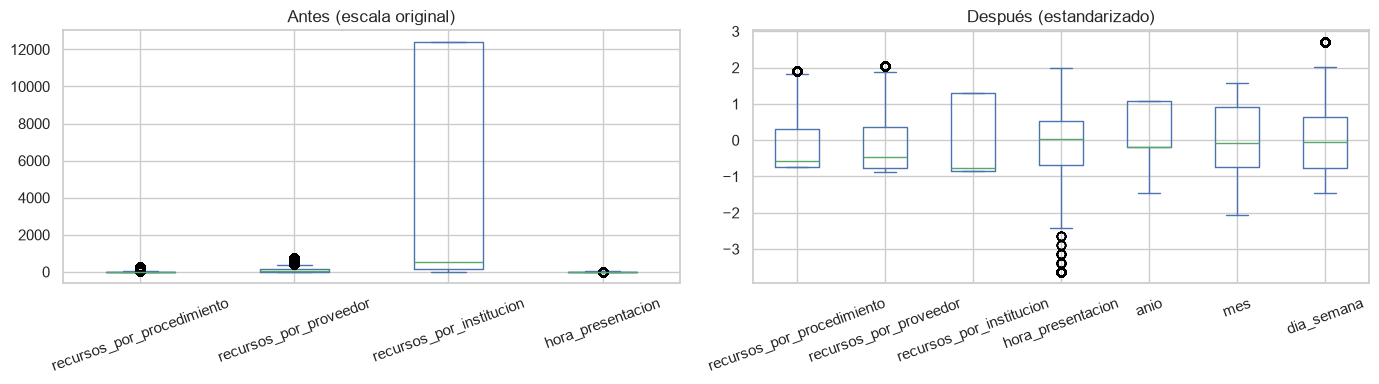

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df_antes_capping[variables_numericas].plot.box(ax=axes[0], rot=20, title="Antes (escala original)")
df[variables_a_escalar].plot.box(ax=axes[1], rot=20, title="Después (estandarizado)")
plt.tight_layout(); plt.show()

## 11. Correlación entre variables
Se calcula la correlación de Pearson entre las variables numéricas y la variable objetivo.

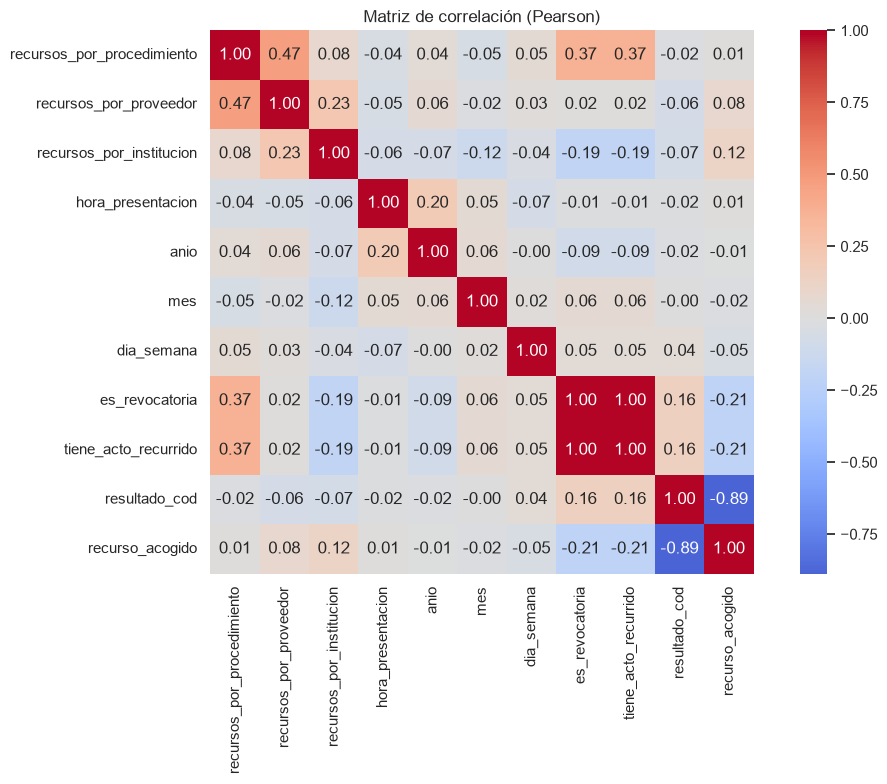

In [36]:
columnas_corr = variables_a_escalar + ["es_revocatoria", "tiene_acto_recurrido",
                                       "resultado_cod", "recurso_acogido"]
matriz_corr = df[columnas_corr].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Matriz de correlación (Pearson)")
plt.tight_layout(); plt.show()

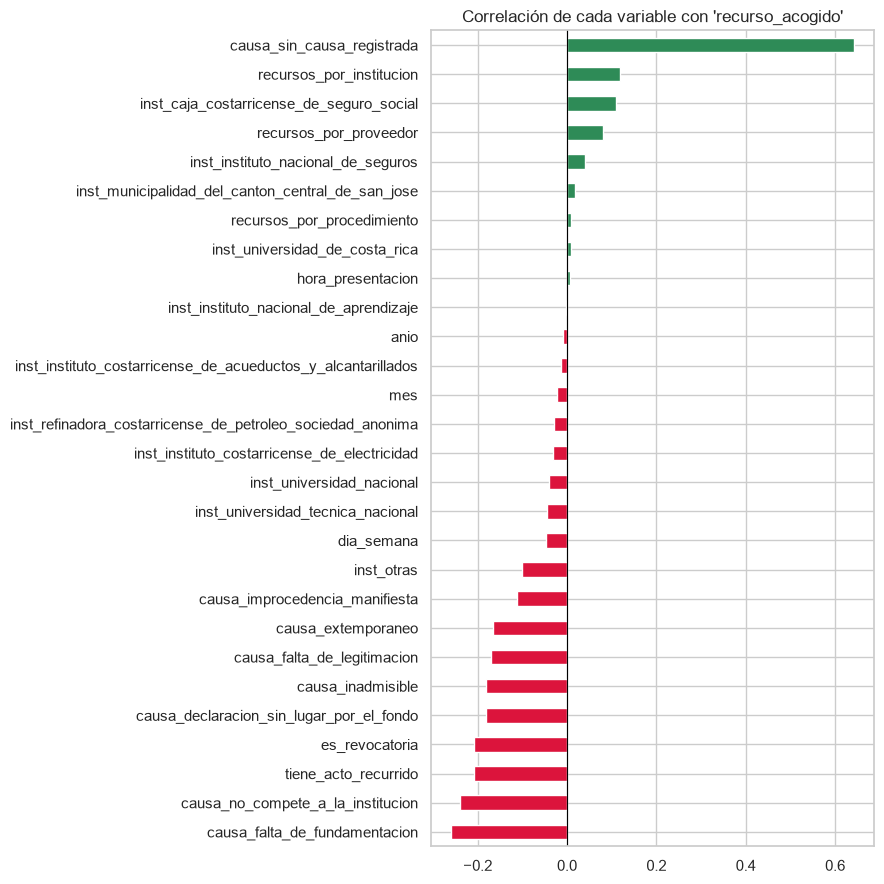

In [37]:
# Correlación de todas las variables numéricas con el objetivo binario 'recurso_acogido'
numericas = df.select_dtypes(include="number").drop(columns=["resultado_cod", "recurso_acogido"])
corr_obj = numericas.corrwith(df["recurso_acogido"]).sort_values()

plt.figure(figsize=(9, 9))
corr_obj.plot.barh(color=["crimson" if v < 0 else "seagreen" for v in corr_obj])
plt.title("Correlación de cada variable con 'recurso_acogido'")
plt.axvline(0, color="black", lw=0.8); plt.tight_layout(); plt.show()

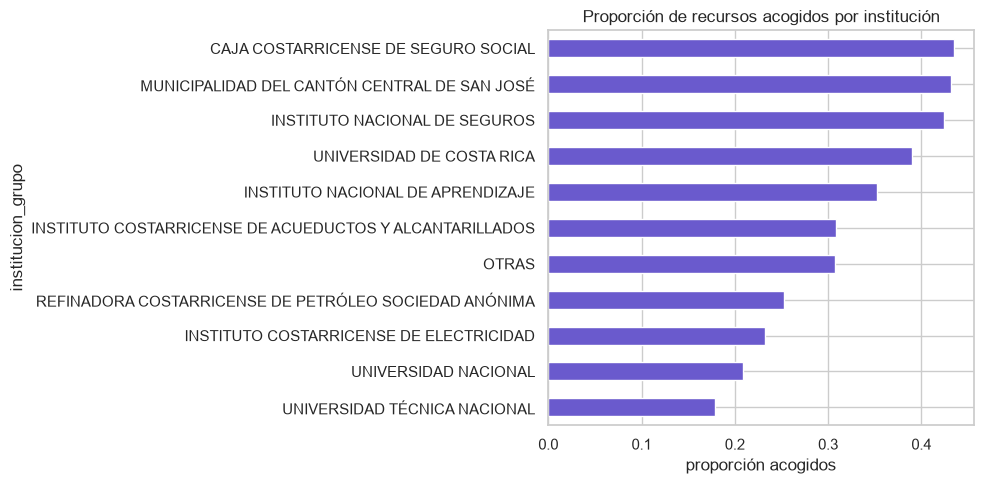

In [38]:
# Proporción de recursos acogidos por institución (relación categórica con el objetivo)
(df.groupby("institucion_grupo")["recurso_acogido"].mean().sort_values()
   .plot.barh(color="slateblue", title="Proporción de recursos acogidos por institución"))
plt.xlabel("proporción acogidos"); plt.tight_layout(); plt.show()

**Hallazgos de correlación**
- `es_revocatoria` y `tiene_acto_recurrido` tienen correlación **1.0**: son la misma información
  (toda revocatoria tiene acto, ninguna objeción lo tiene). Para modelar basta con una de las dos.
- Las *dummies* de `causa_resultado` son las más correlacionadas con el objetivo (p. ej.
  `causa_sin_causa_registrada` positiva, `causa_falta_de_fundamentacion` negativa). Sin embargo, la
  causa **se conoce al mismo tiempo que el resultado**, por lo que usarla como predictor sería
  *fuga de información* (data leakage). Se conserva en el dataset, pero se excluye del modelo.
- `es_revocatoria` tiene correlación negativa (≈ −0,21) con `recurso_acogido`: las **objeciones**
  se acogen con más frecuencia que las revocatorias.
- `recursos_por_institucion` y `inst_caja_costarricense_de_seguro_social` están casi perfectamente
  correlacionadas (≈ 0,99), porque la CCSS es la institución con más recursos; ambas tienen
  correlación positiva (≈ 0,11‑0,12) con el objetivo.
- Las variables de tiempo (hora, mes, año, día) tienen correlación lineal casi nula con el objetivo;
  eso no descarta relaciones no lineales, que un modelo basado en árboles sí puede capturar.

## 12. Variable dependiente y modelo candidato
**Variable dependiente:** `resultado` (resultado de la resolución del recurso), con las clases
*Rechaza de plano*, *Sin lugar*, *Con lugar* y *Parcialmente con lugar*. También se puede plantear
la versión binaria `recurso_acogido` (1 = con lugar total o parcial).

Como la variable objetivo es **categórica**, el problema es de **clasificación** (no de regresión).

**Modelo candidato: Árbol de decisión / Random Forest**, porque:
- La mayoría de los predictores son categóricos codificados (binarios/dummies) y las relaciones no
  son lineales; los árboles manejan bien este tipo de datos.
- Son robustos a los atípicos restantes y no requieren supuestos de distribución.
- Son interpretables (importancia de variables), útil para explicar por qué se acoge un recurso.
- Como alternativas se pueden comparar la **Regresión Logística** (línea base) y **KNN**.

A continuación una prueba rápida, sin las variables de causa (para evitar fuga de información):

In [39]:
predictoras = (["recursos_por_procedimiento", "recursos_por_proveedor", "recursos_por_institucion",
                "hora_presentacion", "anio", "mes", "dia_semana", "es_revocatoria"]
               + [c for c in df.columns if c.startswith("inst_")])
X = df[predictoras]
y = df["recurso_acogido"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

modelos = {
    "Regresión logística": LogisticRegression(max_iter=1000),
    "Árbol de decisión": DecisionTreeClassifier(max_depth=8, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1),
}
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    print(f"{nombre:22s} accuracy = {accuracy_score(y_test, modelo.predict(X_test)):.3f}")
print(f"{'Línea base (clase mayoritaria)':22s} accuracy = {1 - y_test.mean():.3f}")

Regresión logística    accuracy = 0.649
Árbol de decisión      accuracy = 0.718


Random Forest          accuracy = 0.773
Línea base (clase mayoritaria) accuracy = 0.636


              precision    recall  f1-score   support

  No acogido       0.78      0.89      0.83      5442
     Acogido       0.74      0.57      0.65      3116

    accuracy                           0.77      8558
   macro avg       0.76      0.73      0.74      8558
weighted avg       0.77      0.77      0.77      8558



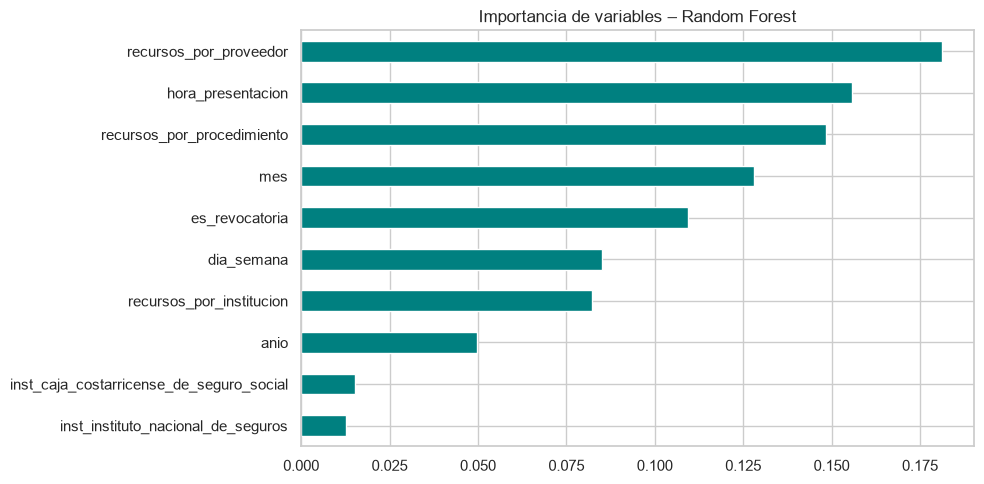

In [40]:
rf = modelos["Random Forest"]
print(classification_report(y_test, rf.predict(X_test), target_names=["No acogido", "Acogido"]))
pd.Series(rf.feature_importances_, index=predictoras).sort_values().tail(10).plot.barh(
    title="Importancia de variables – Random Forest", color="teal")
plt.tight_layout(); plt.show()

**Conclusión:** el Random Forest (≈ 0,77 de exactitud) supera a la línea base de la clase
mayoritaria (≈ 0,64), al árbol de decisión (≈ 0,72) y a la regresión logística (≈ 0,65), lo que
confirma que un modelo de árboles es buen candidato para este problema de **clasificación**. Las
variables más importantes son los recursos por proveedor, la hora de presentación, los recursos por
procedimiento, el mes y el tipo de recurso: relaciones no lineales que la regresión logística no capta.

## 13. Guardar el conjunto de datos procesado
Se guarda el dataset resultante con todas las transformaciones del EDA en `data_process.csv`.

In [41]:
df.to_csv("data_process.csv", index=False, encoding="utf-8")
print("Archivo guardado: data_process.csv", df.shape)
pd.read_csv("data_process.csv").head()

Archivo guardado: data_process.csv (34230, 43)


,cedula_institucion,institucion,numero_procedimiento,numero_recurso,asunto,cedula_proveedor,proveedor,numero_acto_recurrido,tipo_recurso,resultado,causa_resultado,fecha_presentacion,recursos_por_procedimiento,recursos_por_proveedor,recursos_por_institucion,hora_presentacion,tiene_acto_recurrido,anio,mes,dia_semana,es_revocatoria,resultado_cod,recurso_acogido,institucion_grupo,causa_declaracion_sin_lugar_por_el_fondo,causa_extemporaneo,causa_falta_de_fundamentacion,causa_falta_de_legitimacion,causa_improcedencia_manifiesta,causa_inadmisible,causa_no_compete_a_la_institucion,causa_sin_causa_registrada,inst_caja_costarricense_de_seguro_social,inst_instituto_costarricense_de_acueductos_y_alcantarillados,inst_instituto_costarricense_de_electricidad,inst_instituto_nacional_de_aprendizaje,inst_instituto_nacional_de_seguros,inst_municipalidad_del_canton_central_de_san_jose,inst_otras,inst_refinadora_costarricense_de_petroleo_sociedad_anonima,inst_universidad_de_costa_rica,inst_universidad_nacional,inst_universidad_tecnica_nacional
0,4000042147,CAJA COSTARRICENSE DE SEGURO SOCIAL,2019LN-000001-0001100012,7082022000000886,Recurso de Revocatoria,3101137584,MERCADEO DE ARTICULOS DE CONSUMO SOCIEDAD ANONIMA,707447,Revocatoria,Sin lugar,Inadmisible,2022-06-13 15:46:18,1.915363,-0.216477,1.311769,0.037667,1,-1.448345,-0.411873,-1.447827,1,3,0,CAJA COSTARRICENSE DE SEGURO SOCIAL,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0
1,4000042147,CAJA COSTARRICENSE DE SEGURO SOCIAL,2019LN-000001-0001100012,7082022000000899,Recurso de Revocatoria,3101137584,MERCADEO DE ARTICULOS DE CONSUMO SOCIEDAD ANONIMA,707453,Revocatoria,Sin lugar,Inadmisible,2022-06-13 15:46:18,1.915363,-0.216477,1.311769,0.037667,1,-1.448345,-0.411873,-1.447827,1,3,0,CAJA COSTARRICENSE DE SEGURO SOCIAL,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0
2,4000042147,CAJA COSTARRICENSE DE SEGURO SOCIAL,2019LN-000001-0001100012,7082022000000895,Recurso de Revocatoria,3101137584,MERCADEO DE ARTICULOS DE CONSUMO SOCIEDAD ANONIMA,707451,Revocatoria,Sin lugar,Inadmisible,2022-06-13 15:46:18,1.915363,-0.216477,1.311769,0.037667,1,-1.448345,-0.411873,-1.447827,1,3,0,CAJA COSTARRICENSE DE SEGURO SOCIAL,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0
3,4000042147,CAJA COSTARRICENSE DE SEGURO SOCIAL,2019LN-000001-0001100012,7082022000000875,Recurso de Revocatoria,3101302123,MERCADEO DE CONSUMO MERCONSA SOCIEDAD ANONIMA,707440,Revocatoria,Sin lugar,No compete a la institución,2022-06-13 12:18:22,1.915363,-0.693662,1.311769,-0.695751,1,-1.448345,-0.411873,-1.447827,1,3,0,CAJA COSTARRICENSE DE SEGURO SOCIAL,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0
4,4000042147,CAJA COSTARRICENSE DE SEGURO SOCIAL,2019LN-000001-0001100012,7082022000000901,Recurso de Revocatoria,3101137584,MERCADEO DE ARTICULOS DE CONSUMO SOCIEDAD ANONIMA,707440,Revocatoria,Sin lugar,Inadmisible,2022-06-13 15:46:18,1.915363,-0.216477,1.311769,0.037667,1,-1.448345,-0.411873,-1.447827,1,3,0,CAJA COSTARRICENSE DE SEGURO SOCIAL,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0
